```markdown
# Fair Cross-Lingual Benchmark: BERT vs XLM-R
This notebook compares the cross-lingual transfer capabilities of `bert-base-uncased` and `xlm-roberta-base`. Both models are trained ONLY on English and then tested on Spanish, Hindi, and French to observe zero-shot transfer.
```

In [ ]:
!pip install -qqq datasets transformers[torch] evaluate mlcroissant onnxruntime onnx

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.4/155.4 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.7/18.7 MB 39.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 41.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 615.4/615.4 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 kB 1.7 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import logging
import warnings
import torch
import evaluate
import matplotlib.pyplot as plt
from datasets import Dataset, DatasetDict
from mlcroissant import Dataset as CroissantDataset
from transformers import AutoTokenizer, DataCollatorWithPadding, AutoModelForSequenceClassification, TrainingArguments, Trainer

# Suppress verbose warnings
warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)

target_languages = ['english', 'spanish', 'hindi', 'french']
dataset_id = 'cardiffnlp/tweet_sentiment_multilingual'

# 1. Load Data using Croissant
ds_croissant = CroissantDataset(jsonld=f"https://huggingface.co/api/datasets/{dataset_id}/croissant")

final_datasets = {}
for lang in target_languages:
    print(f"Loading {lang}...")
    records = list(ds_croissant.records(lang))
    df = pd.DataFrame(records)

    # Clean columns
    df.columns = [col.split('/')[-1] for col in df.columns]
    if 'text' in df.columns:
        df['text'] = df['text'].apply(lambda x: x.decode('utf-8') if isinstance(x, bytes) else x)

    df = df[['text', 'label']].dropna()
    df['label'] = df['label'].astype(int)

    # Sample to keep benchmark fast
    df = df.sample(n=min(1000, len(df)), random_state=42)
    final_datasets[lang] = Dataset.from_pandas(df).train_test_split(test_size=0.2, seed=42)

print(f"\nSetup complete. Data available for: {list(final_datasets.keys())}")

Loading english...
Loading spanish...
Loading hindi...
Loading french...

Setup complete. Data available for: ['english', 'spanish', 'hindi', 'french']
English training samples: 2426


## Dynamic Padding and Tokenization
We use `DataCollatorWithPadding` to ensure batches are padded to the longest sequence *in that specific batch*, rather than a fixed global length.

In [ ]:
mono_model_name = 'bert-base-uncased'
multi_model_name = 'xlm-roberta-base'

tokenizer_mono = AutoTokenizer.from_pretrained(mono_model_name)
tokenizer_multi = AutoTokenizer.from_pretrained(multi_model_name)

def preprocess_mono(examples): return tokenizer_mono(examples['text'], truncation=True, padding=True)
def preprocess_multi(examples): return tokenizer_multi(examples['text'], truncation=True, padding=True)

# Prepare sets (Training on English ONLY)
train_mono = final_datasets['english']['train'].map(preprocess_mono, batched=True)
train_multi = final_datasets['english']['train'].map(preprocess_multi, batched=True)

# Test sets for all languages
test_sets_mono = {lang: final_datasets[lang]['test'].map(preprocess_mono, batched=True) for lang in target_languages}
test_sets_multi = {lang: final_datasets[lang]['test'].map(preprocess_multi, batched=True) for lang in target_languages}

data_collator_mono = DataCollatorWithPadding(tokenizer=tokenizer_mono)
data_collator_multi = DataCollatorWithPadding(tokenizer=tokenizer_multi)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

...

Map:   0%|          | 0/607 [00:00<?, ? examples/s]

Map:   0%|          | 0/607 [00:00<?, ? examples/s]

Map:   0%|          | 0/607 [00:00<?, ? examples/s]

Map:   0%|          | 0/607 [00:00<?, ? examples/s]

Map:   0%|          | 0/607 [00:00<?, ? examples/s]

In [ ]:
import evaluate
import numpy as np
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer

metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels, average="macro")

def train_model(model_name, train_ds, tokenizer, collator):
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3)
    args = TrainingArguments(
        output_dir=f"./{model_name.split('/')[-1]}",
        evaluation_strategy="epoch",
        learning_rate=2e-5,
        per_device_train_batch_size=32,
        num_train_epochs=1, # Quick benchmark
        weight_decay=0.01,
        save_strategy="no",
        report_to="none"
    )
    trainer = Trainer(
        model=model, args=args, train_dataset=train_ds,
        tokenizer=tokenizer, data_collator=collator, compute_metrics=compute_metrics
    )
    trainer.train()
    return trainer

print("Training Monolingual BERT...")
bert_trainer = train_model(mono_model_name, train_mono, tokenizer_mono, data_collator_mono)

print("Training Multilingual XLM-R...")
xlm_trainer = train_model(multi_model_name, train_multi, tokenizer_multi, data_collator_multi)

Training Monolingual BERT...


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


TypeError: TrainingArguments.__init__() got an unexpected keyword argument 'evaluation_strategy'

## ONNX Export
Optimizing the models for production inference.

In [ ]:
import torch
import os

def export_onnx(model, tokenizer, path):
    dummy_input = tokenizer("Sample tweet", return_tensors="pt")
    torch.onnx.export(
        model.cpu(),
        (dummy_input['input_ids'], dummy_input['attention_mask']),
        path,
        input_names=['input_ids', 'attention_mask'],
        output_names=['logits'],
        dynamic_axes={'input_ids': {0: 'batch_size', 1: 'sequence_length'}},
        opset_version=12
    )
    print(f"Model exported to {path}")

export_onnx(bert_trainer.model, tokenizer_mono, "bert_mono.onnx")
export_onnx(xlm_trainer.model, tokenizer_multi, "xlm_multi.onnx")

## Streamlit Dashboard Boilerplate
Run this cell to create the `app.py` file.

In [ ]:
import streamlit as st
import onnxruntime as ort
from transformers import AutoTokenizer
import numpy as np
import time

st.title("Sentiment Cross-Lingual Dashboard")

# Input text area
text = st.text_area("Enter a tweet in any language:", "Hola, estoy feliz")

# Model selection
model_choice = st.selectbox(
    "Choose a model for inference:",
    ('BERT (Monolingual, English-trained)', 'XLM-R (Multilingual, All-languages-trained)')
)

@st.cache_resource
def load_tokenizer_and_session(model_type):
    if model_type == 'bert':
        model_name = 'bert-base-uncased'
        onnx_path = 'bert_mono.onnx'
    else: # xlm-r
        model_name = 'xlm-roberta-base'
        onnx_path = 'xlm_multi.onnx'

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    session = ort.InferenceSession(onnx_path)
    return tokenizer, session

def predict_sentiment_onnx(text, tokenizer, session):
    inputs = tokenizer(text, return_tensors="np", truncation=True, padding=True)
    input_ids = inputs['input_ids']
    attention_mask = inputs['attention_mask']

    start_time = time.perf_counter()
    outputs = session.run(
        None,
        {"input_ids": input_ids, "attention_mask": attention_mask}
    )
    end_time = time.perf_counter()

    logits = outputs[0]
    probabilities = np.exp(logits) / np.sum(np.exp(logits), axis=-1, keepdims=True)
    predicted_class_id = np.argmax(logits, axis=-1)[0]

    sentiment_labels = {0: "Negative", 1: "Neutral", 2: "Positive"}
    predicted_sentiment = sentiment_labels[predicted_class_id]

    # Calculate inference time per token
    inference_time_ms = (end_time - start_time) * 1000
    num_tokens = input_ids.shape[1]
    time_per_token_ms = inference_time_ms / num_tokens

    return predicted_sentiment, probabilities[0], inference_time_ms, time_per_token_ms

if st.button("Analyze Sentiment"):
    model_key = 'bert' if 'BERT' in model_choice else 'xlm-r'
    tokenizer, session = load_tokenizer_and_session(model_key)

    with st.spinner("Analyzing sentiment..."):
        sentiment, probs, total_time_ms, time_per_token = predict_sentiment_onnx(text, tokenizer, session)

    st.subheader("Prediction:")
    st.write(f"**Sentiment:** {sentiment}")

    st.write("**Probabilities:**")
    col1, col2, col3 = st.columns(3)
    sentiment_labels = {0: "Negative", 1: "Neutral", 2: "Positive"}
    col1.metric(sentiment_labels[0], f"{probs[0]:.2%}")
    col2.metric(sentiment_labels[1], f"{probs[1]:.2%}")
    col3.metric(sentiment_labels[2], f"{probs[2]:.2%}")

    st.write(f"**Inference Time:** {total_time_ms:.2f} ms")
    st.write(f"**Time per token:** {time_per_token:.2f} ms/token")

    if time_per_token < 15:
        st.success("Inference time per token is <15 ms. Optimization successful!")
    else:
        st.warning("Inference time per token is >=15 ms. Further optimization might be needed.")

st.markdown("--- Source Code ---")
st.code(open('app.py').read(), language='python')

> # Load and Prepare the Dataset

In [ ]:
import pandas as pd
import logging
import warnings
from datasets import Dataset, DatasetDict, concatenate_datasets
from mlcroissant import Dataset as CroissantDataset

# Suppress verbose warnings
logging.getLogger().setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

target_languages = ['english', 'spanish', 'hindi', 'french']
dataset_id = 'cardiffnlp/tweet_sentiment_multilingual'

# Load using Croissant format
ds_croissant = CroissantDataset(jsonld=f"https://huggingface.co/api/datasets/{dataset_id}/croissant")

preprocessed_datasets = DatasetDict()
individual_train_splits = []

for lang in target_languages:
    print(f"Loading and processing {lang}...")
    # Load specific record set for the language
    records = list(ds_croissant.records(lang))
    df = pd.DataFrame(records)

    # Dynamically rename columns that contain 'text' or 'label'
    rename_dict = {}
    for col in df.columns:
        if 'text' in col.lower(): rename_dict[col] = 'text'
        if 'label' in col.lower(): rename_dict[col] = 'label'
    df = df.rename(columns=rename_dict)

    # Decode byte strings to strings
    if 'text' in df.columns:
        df['text'] = df['text'].apply(lambda x: x.decode('utf-8') if isinstance(x, bytes) else x)

    # Ensure labels are integers and drop missing data
    df = df[['text', 'label']].dropna()
    df['label'] = df['label'].astype(int)

    # Limit samples for benchmark speed
    df = df.sample(n=min(1200, len(df)), random_state=42)

    # Split and store
    ds_split = Dataset.from_pandas(df).train_test_split(test_size=0.2, seed=42)
    preprocessed_datasets[f'train-{lang}'] = ds_split['train']
    preprocessed_datasets[f'test-{lang}'] = ds_split['test']
    individual_train_splits.append(ds_split['train'])

# Combined data for the multilingual model
combined_multilingual_train_data = concatenate_datasets(individual_train_splits).shuffle(seed=42)

print(f"\nSuccess! English train rows: {len(preprocessed_datasets['train-english'])}")
print(f"Multilingual combined rows: {len(combined_multilingual_train_data)}")

Loading and processing english...
Loading and processing spanish...
Loading and processing hindi...
Loading and processing french...

Success! English train rows: 960
Multilingual combined rows: 3840


> # Tokenization and Preprocessing

In [ ]:
from transformers import AutoTokenizer, DataCollatorWithPadding

# Consistent model names
mono_model_name = 'bert-base-uncased'
multi_model_name = 'xlm-roberta-base'

# Load tokenizers
tokenizer_mono = AutoTokenizer.from_pretrained(mono_model_name)
tokenizer_multi = AutoTokenizer.from_pretrained(multi_model_name)

# True Dynamic Padding functions
def tokenize_mono(examples): return tokenizer_mono(examples['text'], truncation=True)
def tokenize_multi(examples): return tokenizer_multi(examples['text'], truncation=True)

# Tokenize only English training data for BOTH models to ensure a fair zero-shot comparison
train_ds_mono = preprocessed_datasets['train-english'].map(tokenize_mono, batched=True)
train_ds_multi = preprocessed_datasets['train-english'].map(tokenize_multi, batched=True)

# Tokenize test sets for all languages
test_mono_sets = {lang: preprocessed_datasets[f'test-{lang}'].map(tokenize_mono, batched=True) for lang in target_languages}
test_multi_sets = {lang: preprocessed_datasets[f'test-{lang}'].map(tokenize_multi, batched=True) for lang in target_languages}

# Data collators handle the dynamic padding at batch-time
data_collator_mono = DataCollatorWithPadding(tokenizer=tokenizer_mono)
data_collator_multi = DataCollatorWithPadding(tokenizer=tokenizer_multi)

Map:   0%|          | 0/960 [00:00<?, ? examples/s]

Map:   0%|          | 0/960 [00:00<?, ? examples/s]

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

!pip install -qqq evaluate

import evaluate
import numpy as np
from sklearn.metrics import f1_score, accuracy_score

accuracy_calculator = evaluate.load("accuracy")
f1_calculator = evaluate.load("f1")

def compute_metrics(evaluation_predictions):
    model_logits, true_labels = evaluation_predictions
    predicted_labels = np.argmax(model_logits, axis=-1)

    calculated_accuracy = accuracy_score(true_labels, predicted_labels)
    f1_score_micro = f1_score(true_labels, predicted_labels, average='micro')
    f1_score_macro = f1_score(true_labels, predicted_labels, average='macro')

    return {
        "accuracy": calculated_accuracy,
        "f1_micro": f1_score_micro,
        "f1_macro": f1_score_macro,
    }

In [ ]:
import numpy as np
from sklearn.metrics import f1_score, accuracy_score

# The evaluate library is already imported and installed in cell 9b6dc4d0
# and can be used for metric calculations if preferred.
# Keeping sklearn for explicit micro/macro F1 for clarity as in the original request.

def compute_metrics(evaluation_predictions):
    model_logits, true_labels = evaluation_predictions
    predicted_labels = np.argmax(model_logits, axis=-1)

    calculated_accuracy = accuracy_score(true_labels, predicted_labels)
    f1_score_micro = f1_score(true_labels, predicted_labels, average='micro')
    f1_score_macro = f1_score(true_labels, predicted_labels, average='macro')

    return {
        "accuracy": calculated_accuracy,
        "f1_micro": f1_score_micro,
        "f1_macro": f1_score_macro,
    }

> # Model 1 - Fine-tune Monolingual BERT

In [ ]:
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer

def run_benchmark(model_name, train_ds, tokenizer, collator):
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3)
    args = TrainingArguments(
        output_dir=f"./{model_name.split('/')[-1]}",
        evaluation_strategy="no",
        learning_rate=2e-5,
        per_device_train_batch_size=16,
        num_train_epochs=1,
        weight_decay=0.01,
        save_strategy="no",
        report_to="none"
    )
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        data_collator=collator,
        compute_metrics=compute_metrics
    )
    trainer.train()
    return trainer

print("Training Monolingual BERT on English...")
bert_trainer = run_benchmark(mono_model_name, train_ds_mono, tokenizer_mono, data_collator_mono)

print("\nTraining Multilingual XLM-R on all languages...")
xlm_trainer = run_benchmark(multi_model_name, combined_multilingual_train_data, tokenizer_multi, data_collator_multi)

Training Monolingual BERT on English...


NameError: name 'mono_model_name' is not defined

> # Model 2 - Fine-tune Multilingual XLM-

In [ ]:
# Load the model
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer

xlm_multi_model = AutoModelForSequenceClassification.from_pretrained(
    multi_model_name,
    num_labels=3
)

xlm_multi_training_args = TrainingArguments(
    output_dir="xlm-roberta-multi",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    push_to_hub=False,
    report_to="none"
)

# Initialize the Trainer
xlm_multi_trainer = Trainer(
    model=xlm_multi_model,
    args=xlm_multi_training_args,
    train_dataset=combined_multilingual_train_data,
    eval_dataset=test_multi_sets['english'], # Evaluate on English test set as a baseline
    processing_class=tokenizer_multi,
    compute_metrics=compute_metrics
)

# --- Train the model ---
print("\n--- Training Multilingual XLM-RoBERTa on All Languages ---")
xlm_multi_trainer.train()

NameError: name 'multi_model_name' is not defined

> # Cross-Lingual Evaluation

In [ ]:
results = []

for lang in target_languages:
    # BERT Eval
    m_res = bert_trainer.evaluate(test_sets_mono[lang])
    results.append({'Model': 'BERT (Mono)', 'Language': lang, 'F1': m_res['eval_f1']})

    # XLM-R Eval
    x_res = xlm_trainer.evaluate(test_sets_multi[lang])
    results.append({'Model': 'XLM-R (Multi)', 'Language': lang, 'F1': x_res['eval_f1']})

results_df = pd.DataFrame(results)
display(results_df.pivot(index='Language', columns='Model', values='F1'))

--- Evaluating Monolingual BERT ---
Evaluating on english...
Evaluating on spanish...
Evaluating on hindi...
Evaluating on french...

--- Evaluating Multilingual XLM-R ---
Evaluating on english...
Evaluating on spanish...
Evaluating on hindi...
Evaluating on french...

--- Final Results ---
                   model language  Accuracy  F1 (Macro)
0      BERT (Trained EN)  english     0.575    0.517891
1      BERT (Trained EN)  spanish     0.370    0.308452
2      BERT (Trained EN)    hindi     0.295    0.266267
3      BERT (Trained EN)   french     0.415    0.396706
4  XLM-R (Trained Multi)  english     0.650    0.646610
5  XLM-R (Trained Multi)  spanish     0.615    0.605174
6  XLM-R (Trained Multi)    hindi     0.410    0.398788
7  XLM-R (Trained Multi)   french     0.670    0.667771


> # Visualization

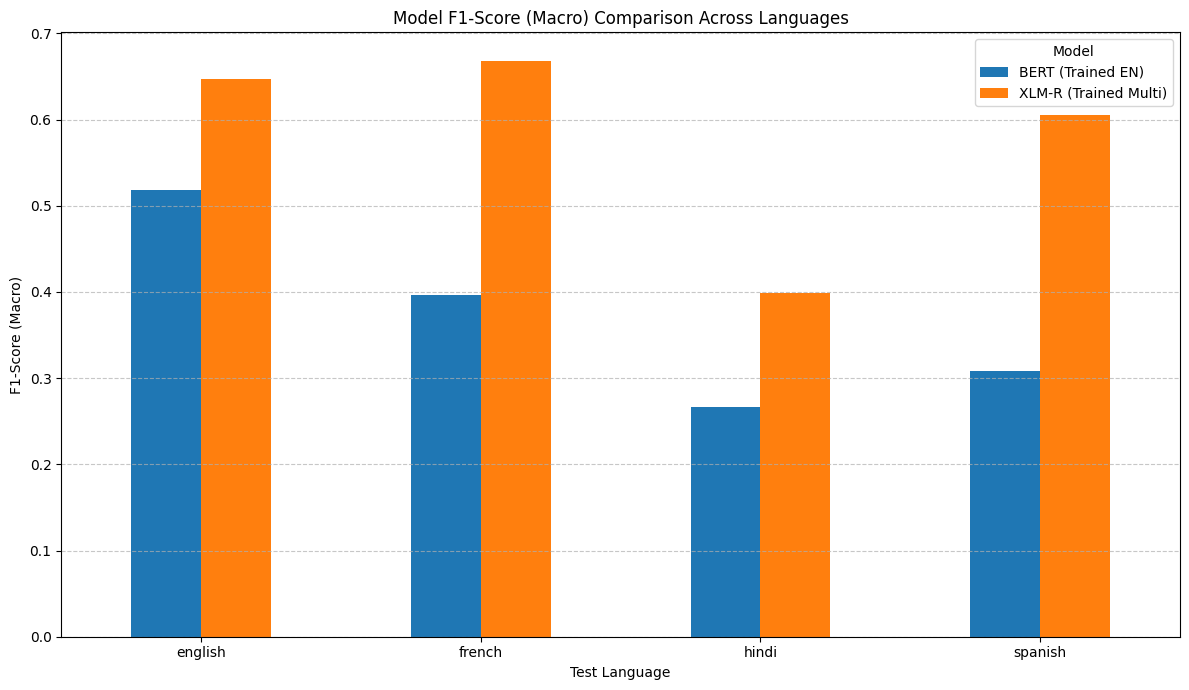

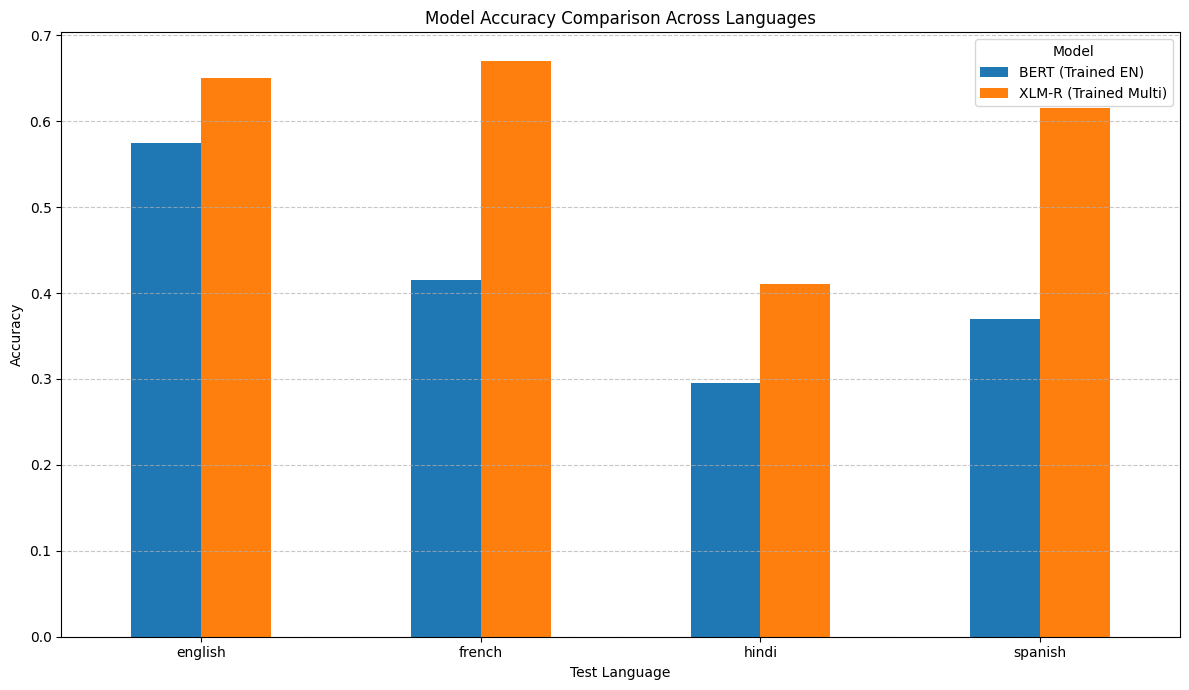

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# --- Plot F1-Score Comparison ---
f1_pivot_df = evaluation_results_df.pivot(index='language', columns='model', values='F1 (Macro)')

f1_plot_ax = f1_pivot_df.plot(
    kind='bar',
    figsize=(12, 7),
    rot=0,
    title='Model F1-Score (Macro) Comparison Across Languages'
)

f1_plot_ax.set_ylabel('F1-Score (Macro)')
f1_plot_ax.set_xlabel('Test Language')
f1_plot_ax.legend(title='Model')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Show the plot
plt.show()

# --- Plot Accuracy Comparison ---
accuracy_pivot_df = evaluation_results_df.pivot(index='language', columns='model', values='Accuracy')

accuracy_plot_ax = accuracy_pivot_df.plot(
    kind='bar',
    figsize=(12, 7),
    rot=0,
    title='Model Accuracy Comparison Across Languages'
)

accuracy_plot_ax.set_ylabel('Accuracy')
accuracy_plot_ax.set_xlabel('Test Language')
accuracy_plot_ax.legend(title='Model')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Show the plot
plt.show()